## 1. Data information and duplicates

In [7]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from scipy import stats
from sklearn.preprocessing import PowerTransformer, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')


In [23]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from scipy import stats
from sklearn.preprocessing import PowerTransformer, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

if os.path.exists('merged_train_test.csv'):
    df = pd.read_csv('merged_train_test.csv')
elif os.path.exists('merged.csv'):
    df = pd.read_csv('merged.csv')
else:
    df = pd.concat([pd.read_csv('train.csv'), pd.read_csv('test.csv')], ignore_index=True)

num = ['Age','Years at Company','Monthly Income','Number of Promotions','Distance from Home','Number of Dependents','Company Tenure']
cat = [c for c in df.columns if c not in num + ['Employee ID']]
print(df.shape, len(num), 'numeric,', len(cat), 'categorical (incl. Attrition)')
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage[missing_percentage > 0])
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

(74498, 24) 7 numeric, 16 categorical (incl. Attrition)
Series([], dtype: float64)
Series([], dtype: int64)


## 2. Quantity: summary statistics and counts

,count,mean,std,min,25%,50%,75%,max,median
Age,74498.0,38.53,12.08,18.0,28.0,39.0,49.0,59.0,39.0
Years at Company,74498.0,15.72,11.22,1.0,7.0,13.0,23.0,51.0,13.0
Monthly Income,74498.0,7299.38,2152.51,1226.0,5652.0,7348.0,8876.0,16149.0,7348.0
Number of Promotions,74498.0,0.83,1.00,0.0,0.0,1.0,2.0,4.0,1.0
Distance from Home,74498.0,49.99,28.51,1.0,25.0,50.0,75.0,99.0,50.0
Number of Dependents,74498.0,1.65,1.55,0.0,0.0,1.0,3.0,6.0,1.0
Company Tenure,74498.0,55.73,25.40,2.0,36.0,56.0,76.0,128.0,56.0


,unique,top,freq,top share %
Gender,2,Male,40826,54.8
Job Role,5,Technology,19322,25.9
Work-Life Balance,4,Good,28158,37.8
Job Satisfaction,4,High,37245,50.0
Performance Rating,4,Average,44719,60.0
Overtime,2,No,50157,67.3
Education Level,5,Bachelor’s Degree,22331,30.0
Marital Status,3,Married,37419,50.2
Job Level,3,Entry,29780,40.0
Company Size,3,Medium,37231,50.0


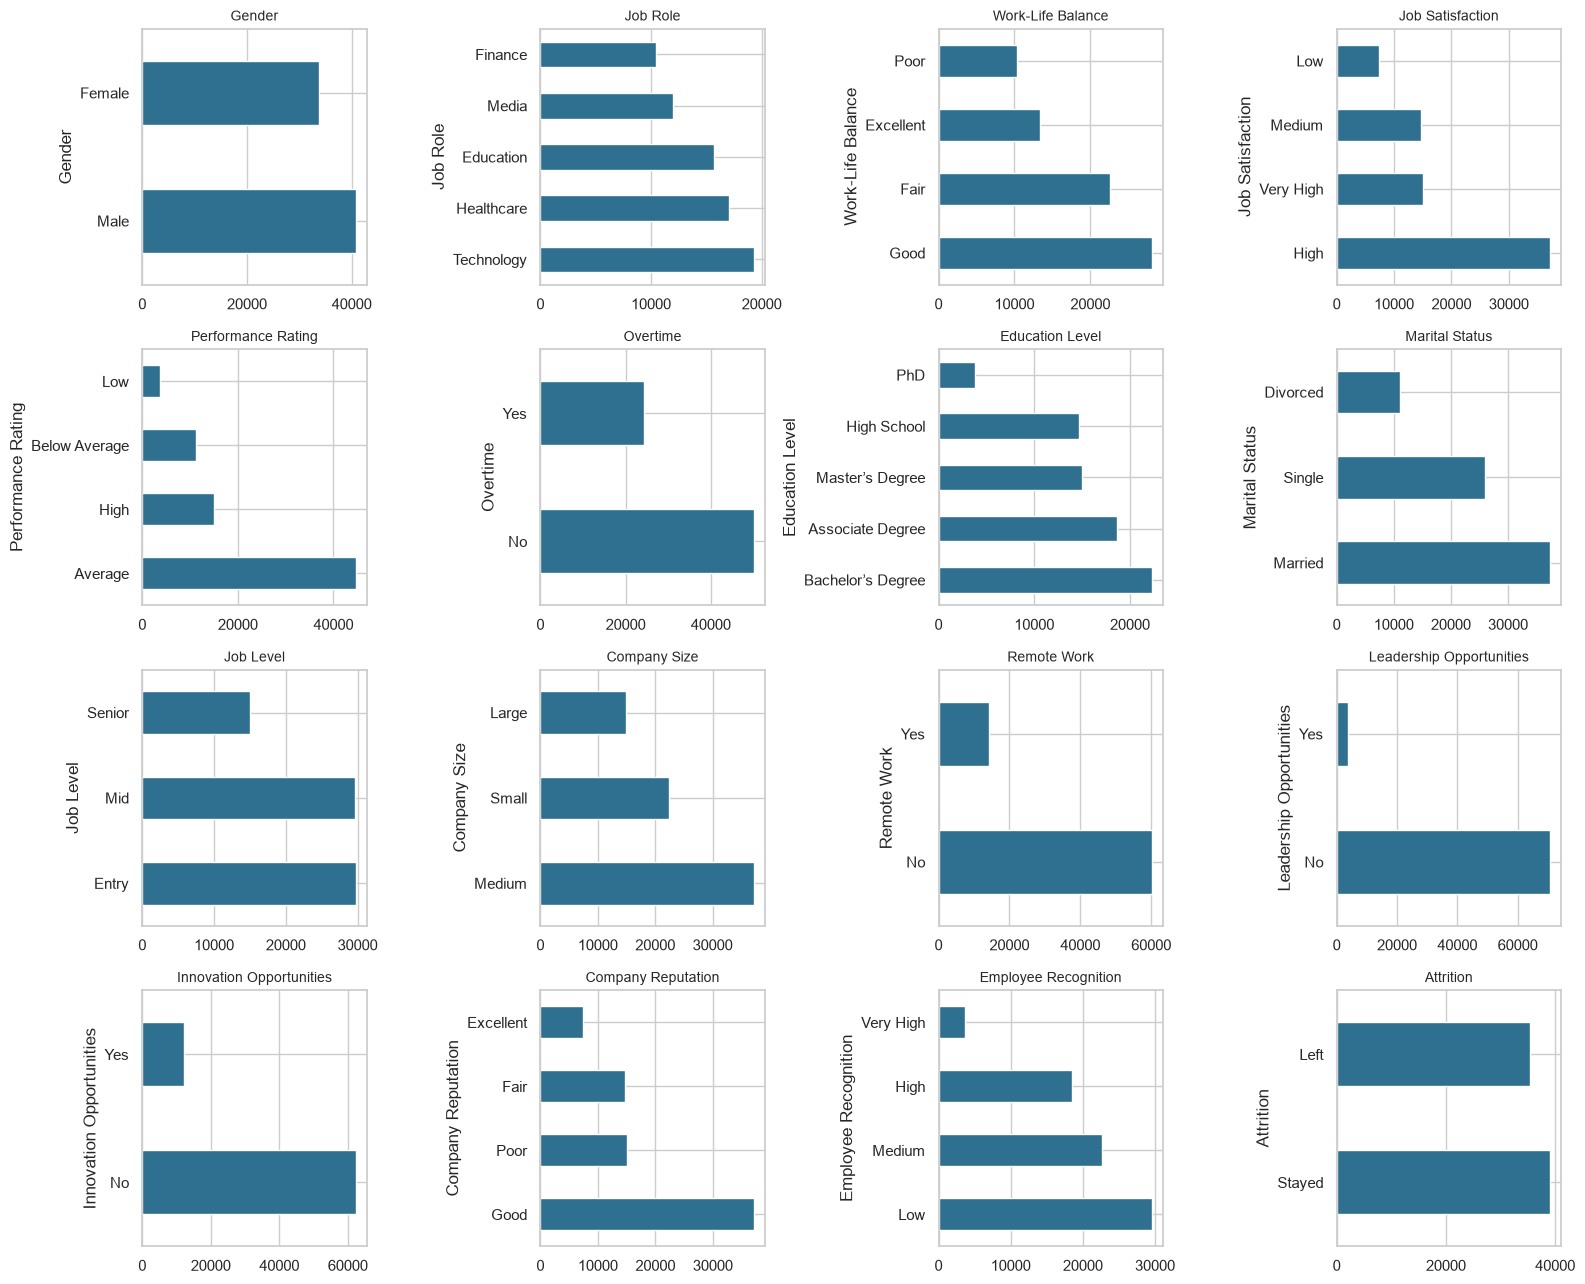

In [9]:
q = df[num].describe().T; q['median'] = df[num].median()
display(q.round(2))
qc = df[cat].describe().T[['unique','top','freq']]; qc['top share %'] = (qc['freq']/len(df)*100).round(1)
display(qc)
fig, ax = plt.subplots(4, 4, figsize=(16, 13)); ax = ax.ravel()
for a, c in zip(ax, cat):
    df[c].value_counts().plot.barh(ax=a, color='#2f6f8f'); a.set_title(c, fontsize=10)
for a in ax[len(cat):]: a.axis('off')
plt.tight_layout(); plt.show()

## 3. Outliers (IQR rule and z-score)
Number of Promotions has only values 0 to 4, so its z-score outliers are not real outliers.

,IQR outliers,IQR %,|z|>3,lower fence,upper fence
column,,,,,
Age,0,0.00,0,-3.5,80.5
Years at Company,338,0.45,88,-17.0,47.0
Monthly Income,65,0.09,59,816.0,13712.0
Number of Promotions,0,0.00,989,-3.0,5.0
Distance from Home,0,0.00,0,-50.0,150.0
Number of Dependents,0,0.00,0,-4.5,7.5
Company Tenure,0,0.00,0,-24.0,136.0


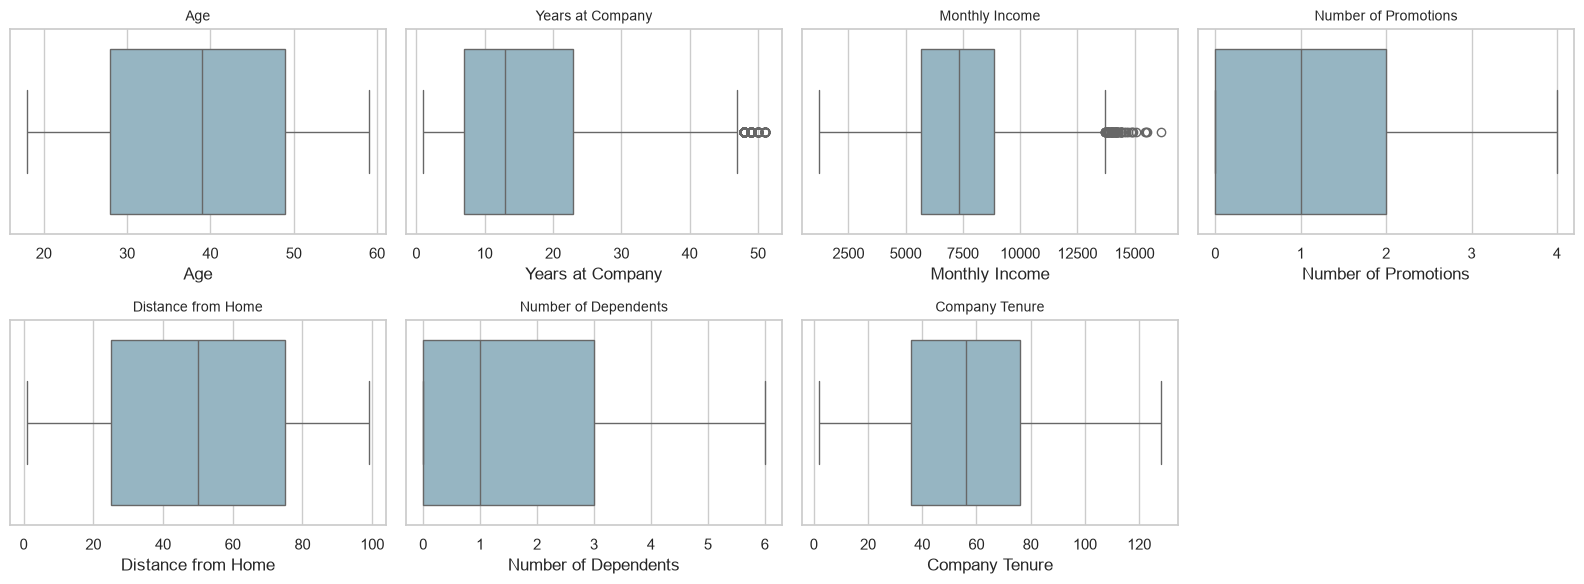

In [10]:
rows = []
for c in num:
    x = df[c]; q1, q3 = x.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5*i, q3 + 1.5*i
    m = (x < lo) | (x > hi)
    rows.append([c, int(m.sum()), round(m.mean()*100, 2), int((np.abs(stats.zscore(x)) > 3).sum()), lo, hi])
out = pd.DataFrame(rows, columns=['column','IQR outliers','IQR %','|z|>3','lower fence','upper fence']).set_index('column')
display(out.round(2))
fig, ax = plt.subplots(2, 4, figsize=(16, 6)); ax = ax.ravel()
for a, c in zip(ax, num): sns.boxplot(x=df[c], ax=a, color='#8fb8c9'); a.set_title(c, fontsize=10)
ax[-1].axis('off'); plt.tight_layout(); plt.show()

## 4. Variance

In [11]:
v = pd.DataFrame({'variance': df[num].var(), 'std': df[num].std(), 'mean': df[num].mean()})
v['CV %'] = v['std'] / v['mean'] * 100
display(v.round(2))
dom = pd.Series({c: df[c].value_counts(normalize=True).iloc[0]*100 for c in cat}, name='dominant value share %').round(1)
display(dom.sort_values(ascending=False).to_frame())

,variance,std,mean,CV %
Age,146.01,12.08,38.53,31.36
Years at Company,125.97,11.22,15.72,71.39
Monthly Income,4633293.13,2152.51,7299.38,29.49
Number of Promotions,0.99,1.00,0.83,119.49
Distance from Home,813.03,28.51,49.99,57.04
Number of Dependents,2.41,1.55,1.65,94.14
Company Tenure,645.13,25.40,55.73,45.58


,dominant value share %
Leadership Opportunities,95.1
Innovation Opportunities,83.8
Remote Work,80.9
Overtime,67.3
Performance Rating,60.0
Gender,54.8
Attrition,52.5
Marital Status,50.2
Company Size,50.0
Job Satisfaction,50.0


### 4b. Variance tests (equal variance across groups)
Levene (median) and Fligner-Killeen do not assume normality. Bartlett does, so it is shown only for comparison. p < 0.05 means the spread differs between groups.

In [12]:
gcols = ['Attrition','Job Role','Marital Status','Job Level','Company Size','Education Level','Gender']
tests = {'Levene (median)': lambda g: stats.levene(*g, center='median')[1],
         'Bartlett': lambda g: stats.bartlett(*g)[1],
         'Fligner-Killeen': lambda g: stats.fligner(*g)[1]}
for name, fn in tests.items():
    t = pd.DataFrame({gc: {c: fn([x[c].values.astype(float) for _, x in df.groupby(gc)]) for c in num} for gc in gcols})
    print(name, '- p-values'); display(t.round(4))

Levene (median) - p-values


,Attrition,Job Role,Marital Status,Job Level,Company Size,Education Level,Gender
Age,0.0000,0.7042,0.2575,0.7476,0.2385,0.5780,0.2767
Years at Company,0.0001,0.9426,0.1265,0.0104,0.0995,0.5275,0.6817
Monthly Income,0.0078,0.0000,0.7532,0.9106,0.2867,0.7911,0.0679
Number of Promotions,0.0000,0.9031,0.5838,0.3786,0.9084,0.6076,0.7819
Distance from Home,0.2788,0.6009,0.2701,0.7914,0.4610,0.1362,0.5475
Number of Dependents,0.0000,0.5945,0.5622,0.4666,0.2119,0.3872,0.9411
Company Tenure,0.8903,0.3801,0.6565,0.3568,0.8059,0.6925,0.3264


Bartlett - p-values


,Attrition,Job Role,Marital Status,Job Level,Company Size,Education Level,Gender
Age,0.0000,0.9579,0.5015,0.9831,0.6892,0.8859,0.6125
Years at Company,0.0965,0.7997,0.1936,0.0131,0.0922,0.4108,0.7708
Monthly Income,0.0542,0.0000,0.8237,0.7831,0.7874,0.5705,0.2036
Number of Promotions,0.0000,0.4853,0.5018,0.3930,0.8495,0.0720,0.7911
Distance from Home,0.5002,0.8814,0.5483,0.9547,0.7331,0.6122,0.6841
Number of Dependents,0.0000,0.5027,0.8069,0.5114,0.4224,0.3620,0.8152
Company Tenure,0.9521,0.5859,0.9087,0.4942,0.7492,0.9477,0.4805


Fligner-Killeen - p-values


,Attrition,Job Role,Marital Status,Job Level,Company Size,Education Level,Gender
Age,0.0000,0.8185,0.1413,0.9315,0.3283,0.6944,0.5259
Years at Company,0.0000,0.9281,0.1314,0.0142,0.0803,0.6450,0.6531
Monthly Income,0.0115,0.0000,0.7583,0.8876,0.3410,0.6953,0.0753
Number of Promotions,0.0000,0.0003,0.0000,0.3644,0.8105,0.0000,0.8606
Distance from Home,0.2159,0.4504,0.2773,0.7916,0.4472,0.5013,0.5668
Number of Dependents,0.0000,0.6299,0.5927,0.4595,0.2136,0.3940,0.9114
Company Tenure,0.9708,0.3393,0.8073,0.3432,0.7169,0.8048,0.3444


In [13]:
# VarianceThreshold on binary columns only (0/1 variance = p(1-p); below 0.1 means one value covers ~89%+ of rows)
bins = ['Gender','Overtime','Remote Work','Leadership Opportunities','Innovation Opportunities','Attrition']
pos = {'Gender': 'Male', 'Attrition': 'Left'}
B = pd.DataFrame({c: (df[c] == pos.get(c, 'Yes')).astype(int) for c in bins})
vt = VarianceThreshold(0.1).fit(B)
display(pd.DataFrame({'variance': B.var(ddof=0), 'verdict': np.where(vt.get_support(), 'kept', 'removed (near-constant)')}).round(4))

,variance,verdict
Gender,0.2477,kept
Overtime,0.2200,kept
Remote Work,0.1543,kept
Leadership Opportunities,0.0466,removed (near-constant)
Innovation Opportunities,0.1361,kept
Attrition,0.2494,kept


## 5. Normality, skewness and kurtosis
With n this large, formal tests reject normality for tiny deviations, so judge by skew (|skew| <= 1), excess kurtosis (|kurt| <= 1) and the Q-Q plot.

,skew,excess kurtosis,Shapiro p (n=5000),D'Agostino p,KS statistic,shape verdict
column,,,,,,
Age,-0.0016,-1.1905,0.0,0.0,0.0676,not normal-like
Years at Company,0.7899,-0.1228,0.0,0.0,0.1071,acceptable
Monthly Income,0.1183,-0.6023,0.0,0.0,0.0416,acceptable
Number of Promotions,0.9928,0.1735,0.0,0.0,0.2973,acceptable
Distance from Home,0.0018,-1.1957,0.0,0.0,0.0617,not normal-like
Number of Dependents,0.7071,-0.4725,0.0,0.0,0.2205,acceptable
Company Tenure,0.0657,-0.7908,0.0,0.0,0.0424,acceptable


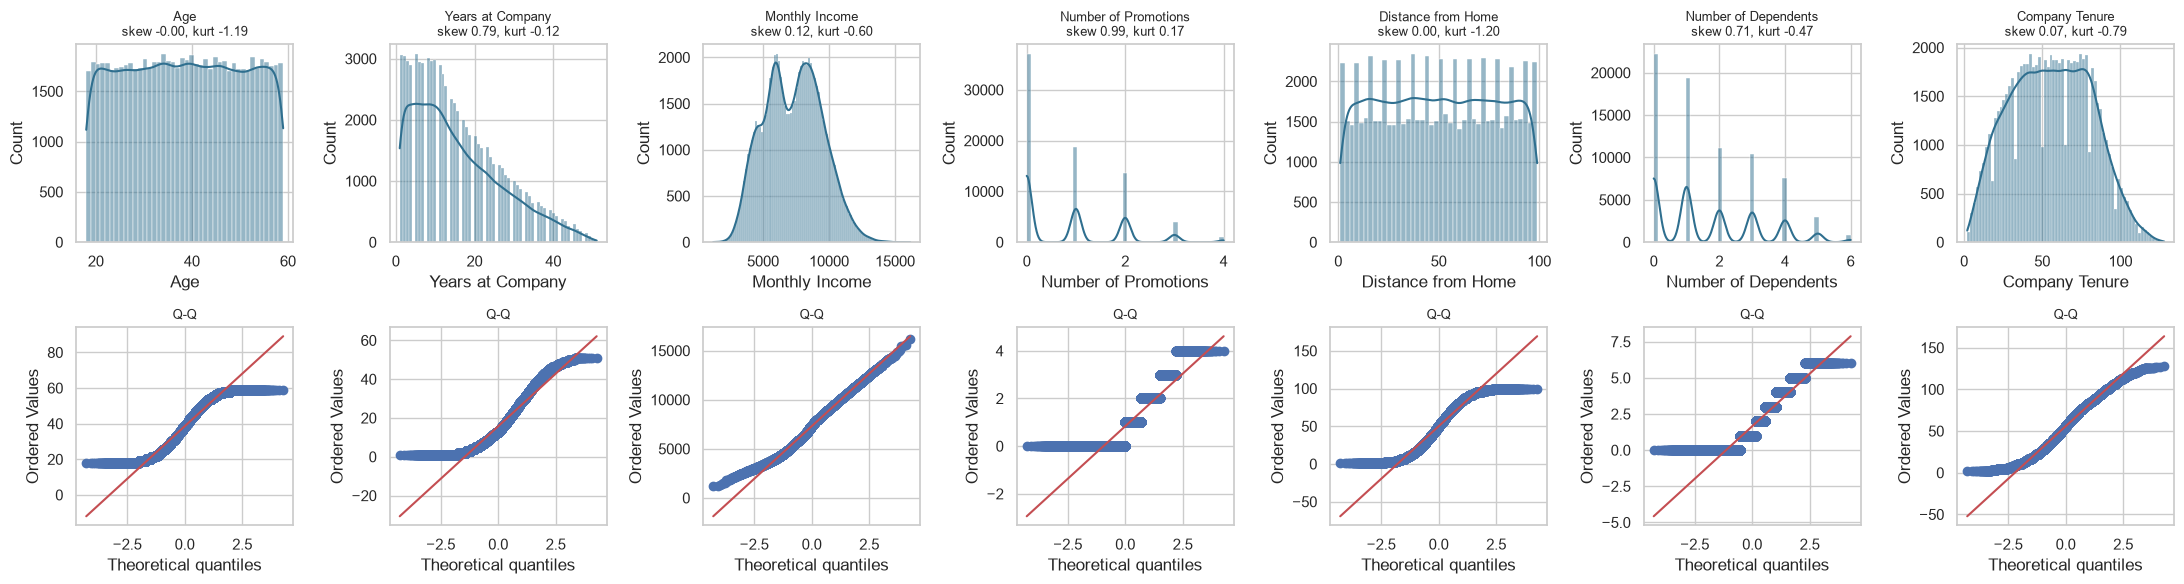

In [14]:
rows = []
for c in num:
    x = df[c]
    rows.append([c, x.skew(), x.kurt(), stats.shapiro(x.sample(5000, random_state=0))[1], stats.normaltest(x)[1], stats.kstest(stats.zscore(x), 'norm')[0]])
nrm = pd.DataFrame(rows, columns=['column','skew','excess kurtosis','Shapiro p (n=5000)',"D'Agostino p",'KS statistic']).set_index('column')
nrm['shape verdict'] = np.where((nrm['skew'].abs() <= 1) & (nrm['excess kurtosis'].abs() <= 1), 'acceptable', 'not normal-like')
display(nrm.round(4))
fig, ax = plt.subplots(2, 7, figsize=(22, 6))
for j, c in enumerate(num):
    sns.histplot(df[c], kde=True, ax=ax[0, j], color='#2f6f8f')
    ax[0, j].set_title('%s\nskew %.2f, kurt %.2f' % (c, nrm.loc[c, 'skew'], nrm.loc[c, 'excess kurtosis']), fontsize=9)
    stats.probplot(df[c], plot=ax[1, j]); ax[1, j].set_title('Q-Q', fontsize=9)
plt.tight_layout(); plt.show()

### 5b. Solution if skew or kurtosis is high (Yeo-Johnson)
A power transform fixes skew. It cannot fix flat (negative-kurtosis) shapes, so for those keep the column as is for tree models, or standardise it for linear models.

In [15]:
bad = nrm[(nrm['skew'].abs() > 1) | (nrm['excess kurtosis'].abs() > 1)].index.tolist()
cols = bad if bad else num
t = pd.DataFrame(PowerTransformer('yeo-johnson').fit_transform(df[cols]), columns=cols)
display(pd.DataFrame({'skew before': df[cols].skew(), 'skew after': t.skew(), 'kurt before': df[cols].kurt(), 'kurt after': t.kurt()}).round(3))

,skew before,skew after,kurt before,kurt after
Age,-0.002,-0.099,-1.190,-1.169
Distance from Home,0.002,-0.250,-1.196,-1.050


## 6. Encoding, correlation heatmap and multicollinearity (VIF)
Ordinal columns keep their natural order, binary columns are 0/1, Attrition is Left = 1. Job Role and Marital Status are nominal, so they are tested in section 8 instead.

Unmapped values: 0


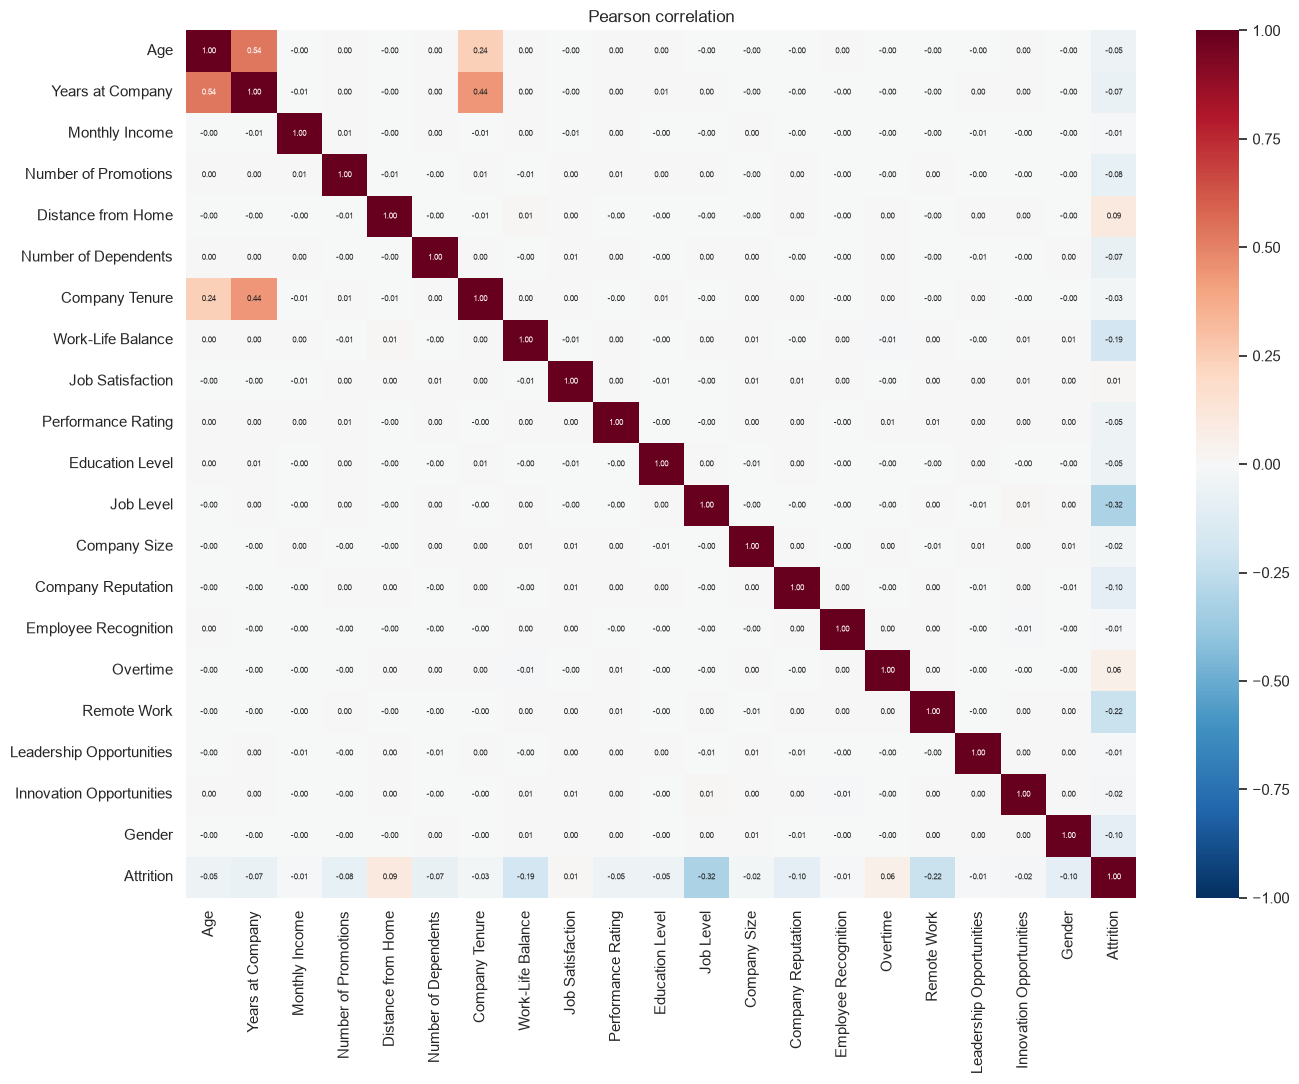

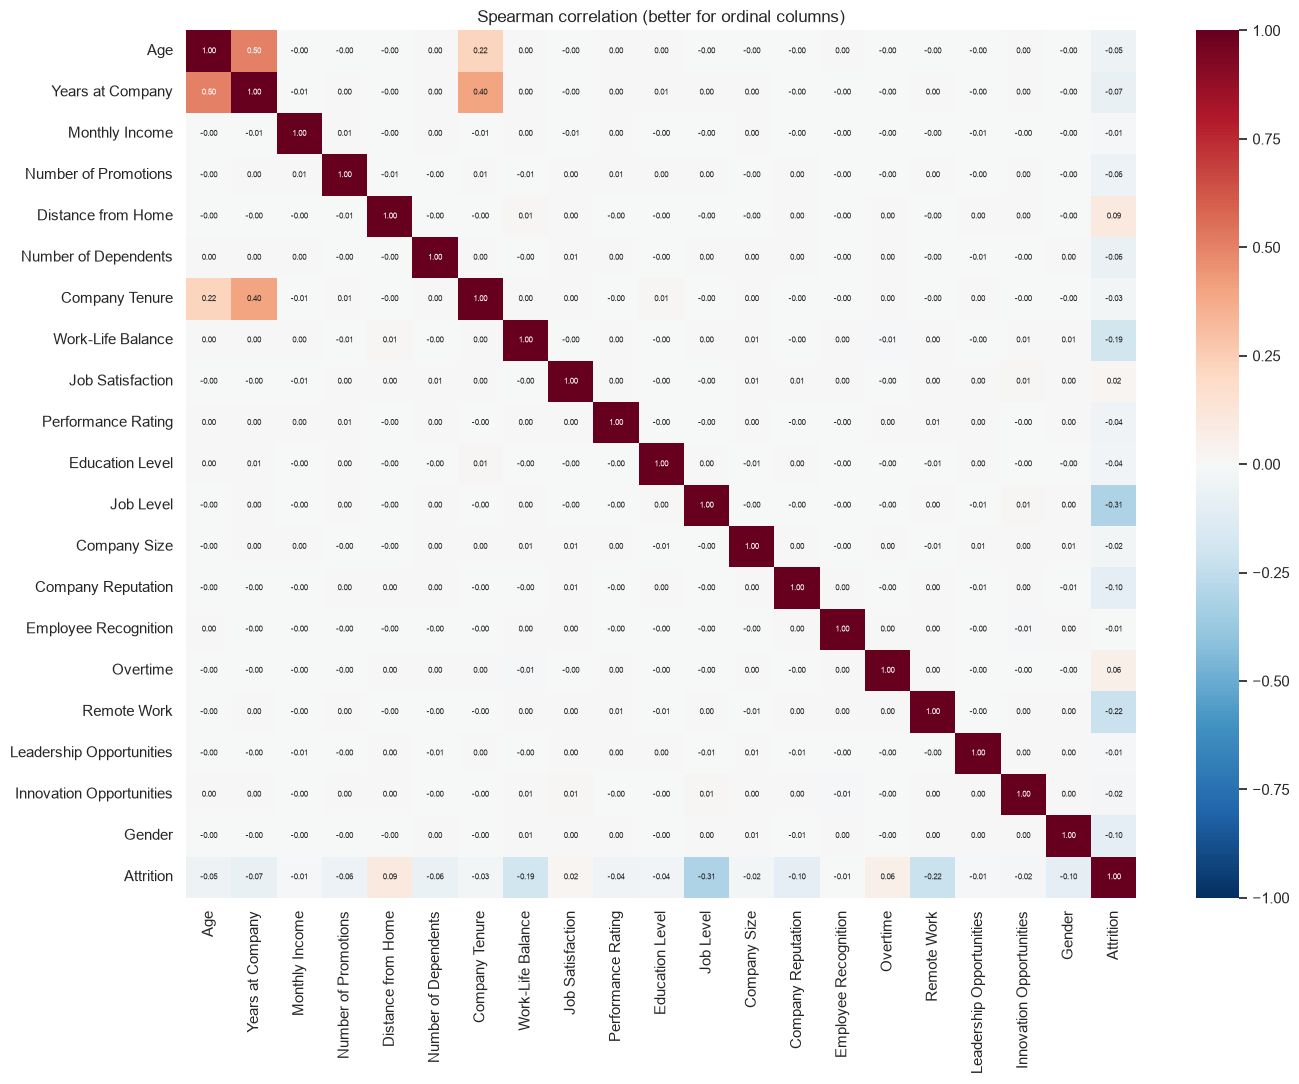

,level_0,level_1,r,|r|
1,Age,Years at Company,0.537,0.537
27,Years at Company,Company Tenure,0.443,0.443
251,Job Level,Attrition,-0.315,0.315
6,Age,Company Tenure,0.236,0.236
356,Remote Work,Attrition,-0.221,0.221
167,Work-Life Balance,Attrition,-0.186,0.186
293,Company Reputation,Attrition,-0.101,0.101
419,Gender,Attrition,-0.101,0.101
104,Distance from Home,Attrition,0.094,0.094
83,Number of Promotions,Attrition,-0.081,0.081


,VIF
Years at Company,1.651
Age,1.406
Company Tenure,1.244
Work-Life Balance,1.001
Company Size,1.000
Innovation Opportunities,1.000
Job Satisfaction,1.000
Education Level,1.000
Number of Promotions,1.000
Overtime,1.000


In [16]:
ordmap = {'Work-Life Balance': ['Poor','Fair','Good','Excellent'], 'Job Satisfaction': ['Low','Medium','High','Very High'],
          'Performance Rating': ['Low','Below Average','Average','High'],
          'Education Level': ['High School','Associate Degree','Bachelor’s Degree','Master’s Degree','PhD'],
          'Job Level': ['Entry','Mid','Senior'], 'Company Size': ['Small','Medium','Large'],
          'Company Reputation': ['Poor','Fair','Good','Excellent'], 'Employee Recognition': ['Low','Medium','High','Very High']}
enc = df[num].copy()
for c, order in ordmap.items(): enc[c] = df[c].map({k: i for i, k in enumerate(order)})
for c in ['Overtime','Remote Work','Leadership Opportunities','Innovation Opportunities']: enc[c] = (df[c] == 'Yes').astype(int)
enc['Gender'] = (df['Gender'] == 'Male').astype(int); enc['Attrition'] = (df['Attrition'] == 'Left').astype(int)
print('Unmapped values:', int(enc.isna().sum().sum()))

pear, spear = enc.corr(), enc.corr(method='spearman')
for title, m in [('Pearson correlation', pear), ('Spearman correlation (better for ordinal columns)', spear)]:
    plt.figure(figsize=(14, 11)); sns.heatmap(m, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot_kws={'size': 6})
    plt.title(title); plt.tight_layout(); plt.show()

pr = pear.where(np.triu(np.ones(pear.shape), 1).astype(bool)).stack().rename('r').reset_index()
pr['|r|'] = pr['r'].abs(); pr = pr.sort_values('|r|', ascending=False)
display(pr.head(10).round(3))

X = enc.drop(columns='Attrition')
vif = pd.Series(np.diag(np.linalg.inv(X.corr().values)), index=X.columns, name='VIF').sort_values(ascending=False)
display(vif.round(3).to_frame())  # above 5 is a concern, above 10 is serious

## 7. Correlation network
Links show |r| >= 0.1 (blue positive, red negative, thicker is stronger). Attrition is the red node.

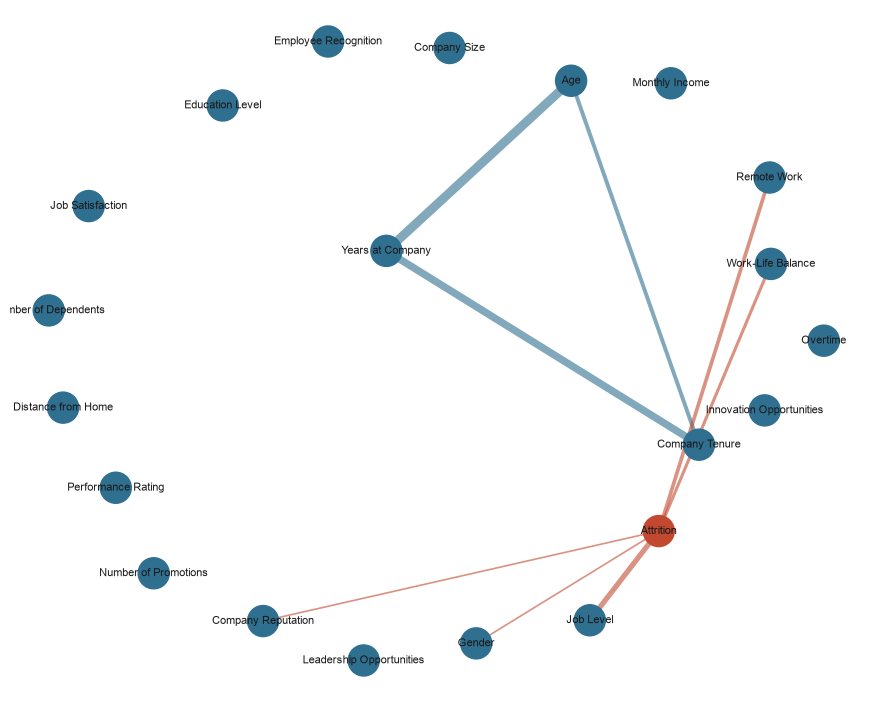

In [17]:
thr = 0.1
G = nx.Graph(); G.add_nodes_from(enc.columns)
for _, r in pr[pr['|r|'] >= thr].iterrows(): G.add_edge(r['level_0'], r['level_1'], w=r['|r|'], s=r['r'])
pos_ = nx.spring_layout(G, seed=3, k=1.2, weight='w'); ed = list(G.edges(data=True))
plt.figure(figsize=(11, 9))
nx.draw_networkx_nodes(G, pos_, node_color=['#c2492f' if n == 'Attrition' else '#2f6f8f' for n in G], node_size=500)
nx.draw_networkx_edges(G, pos_, edgelist=[(a, b) for a, b, _ in ed], width=[x['w']*12 for *_, x in ed],
                       edge_color=['#c2492f' if x['s'] < 0 else '#2f6f8f' for *_, x in ed], alpha=.6)
nx.draw_networkx_labels(G, pos_, font_size=8); plt.axis('off'); plt.show()

## 8. Independence: categorical features vs Attrition (chi-square, Cramér V)
With this many rows almost everything has p < 0.05, so use Cramér V for size (about 0.1 small, 0.3 medium, 0.5 large).

,chi2,p-value,Cramér V,independent of Attrition?
feature,,,,
Job Level,7496.5071,0.0000,0.3172,no (dependent)
Marital Status,6046.9596,0.0000,0.2849,no (dependent)
Remote Work,3643.7366,0.0000,0.2212,no (dependent)
Work-Life Balance,2912.4974,0.0000,0.1977,no (dependent)
Company Reputation,887.5875,0.0000,0.1092,no (dependent)
Education Level,859.3168,0.0000,0.1074,no (dependent)
Gender,754.0996,0.0000,0.1006,no (dependent)
Job Satisfaction,388.2373,0.0000,0.0722,no (dependent)
Performance Rating,257.1071,0.0000,0.0587,no (dependent)


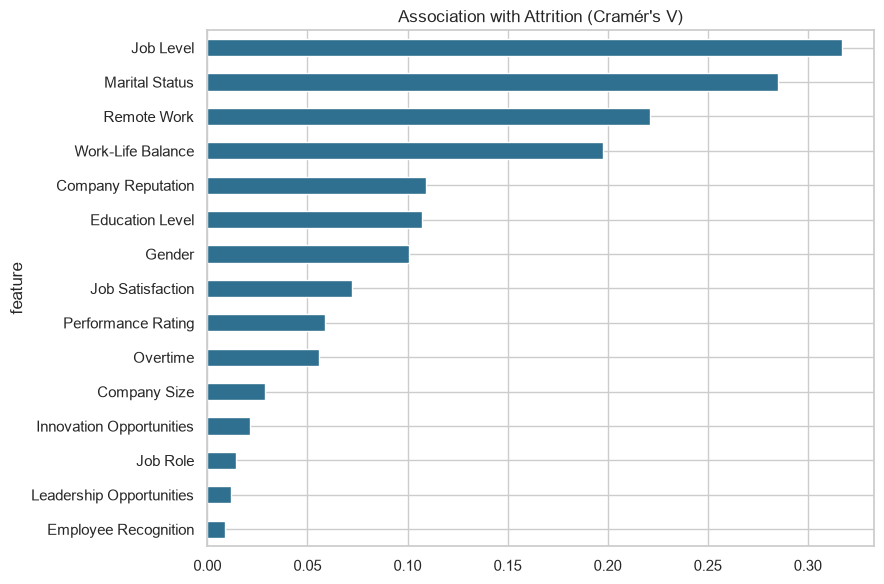

In [18]:
def cramers(a, b):
    ct = pd.crosstab(a, b); chi, p, _, _ = stats.chi2_contingency(ct); n = ct.values.sum()
    return chi, p, np.sqrt(chi / (n * (min(ct.shape) - 1)))
ind = pd.DataFrame([(c,) + cramers(df[c], df['Attrition']) for c in cat if c != 'Attrition'],
                   columns=['feature','chi2','p-value','Cramér V']).set_index('feature').sort_values('Cramér V', ascending=False)
ind['independent of Attrition?'] = np.where(ind['p-value'] < 0.05, 'no (dependent)', 'yes (fail to reject)')
display(ind.round(4))
ind['Cramér V'].sort_values().plot.barh(figsize=(9, 6), color='#2f6f8f', title="Association with Attrition (Cramér's V)"); plt.tight_layout(); plt.show()

## 9. Comparison by mean and normality check
Left vs Stayed: Welch t-test (unequal variance allowed), Mann-Whitney U (no normality assumed), Cohen d for effect size, Shapiro per group, Levene for equal variance.

,mean Left,mean Stayed,diff,Welch p,Mann-Whitney p,Cohen d,Shapiro p Left,Shapiro p Stayed,Levene p
column,,,,,,,,,
Age,37.8841,39.1134,-1.2293,0.0000,0.0000,-0.1018,0.0,0.0,0.0000
Years at Company,14.9497,16.4194,-1.4697,0.0000,0.0000,-0.1313,0.0,0.0,0.0001
Monthly Income,7275.1839,7321.2513,-46.0674,0.0036,0.0036,-0.0214,0.0,0.0,0.0078
Number of Promotions,0.7480,0.9098,-0.1618,0.0000,0.0000,-0.1638,0.0,0.0,0.0000
Distance from Home,52.8057,47.4477,5.3580,0.0000,0.0000,0.1888,0.0,0.0,0.2788
Number of Dependents,1.5284,1.7605,-0.2321,0.0000,0.0000,-0.1502,0.0,0.0,0.0000
Company Tenure,54.9537,56.4269,-1.4732,0.0000,0.0000,-0.0580,0.0,0.0,0.8903


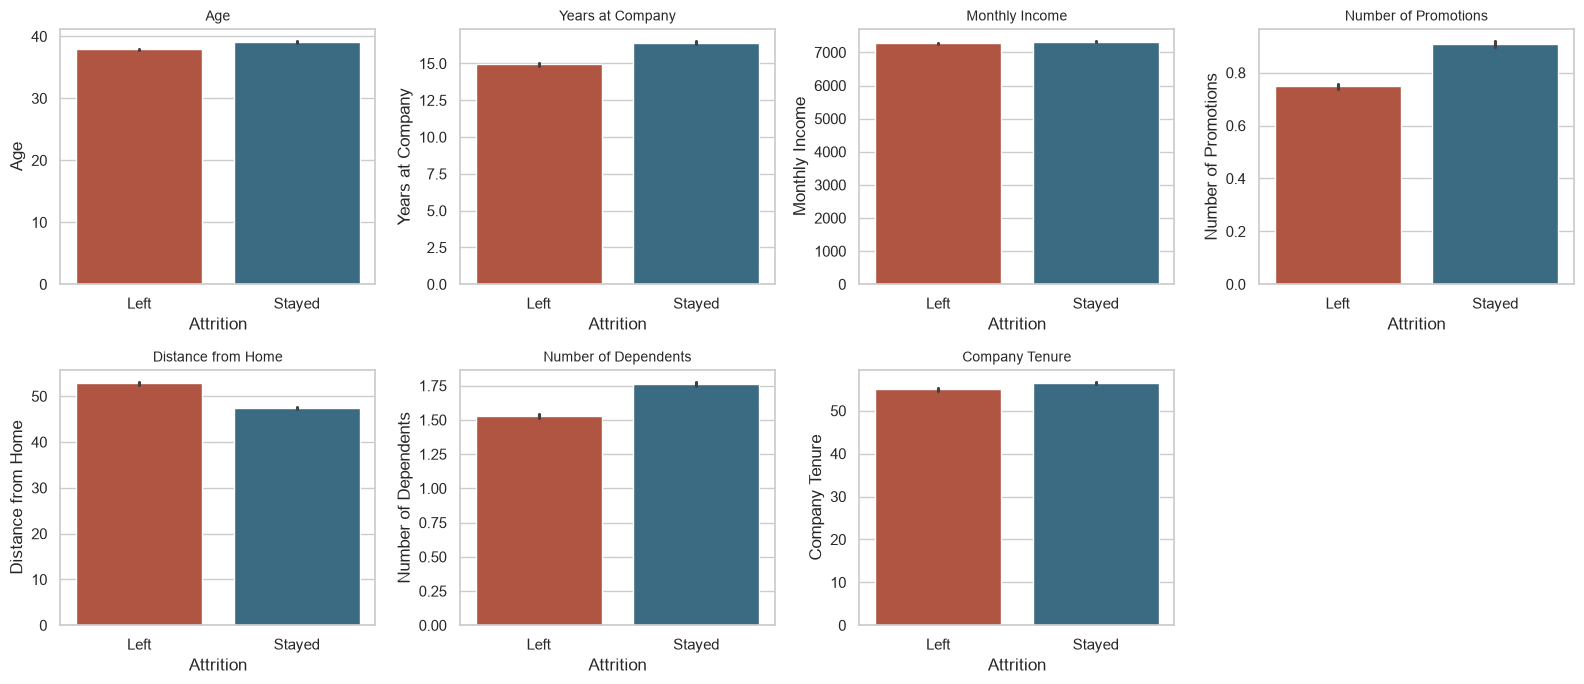

In [19]:
rows = []
for c in num:
    a, b = df.loc[df.Attrition == 'Left', c], df.loc[df.Attrition == 'Stayed', c]
    t, pt = stats.ttest_ind(a, b, equal_var=False); pu = stats.mannwhitneyu(a, b)[1]
    sp = np.sqrt((a.var() + b.var()) / 2)
    rows.append([c, a.mean(), b.mean(), a.mean() - b.mean(), pt, pu, (a.mean() - b.mean()) / sp,
                 stats.shapiro(a.sample(5000, random_state=0))[1], stats.shapiro(b.sample(5000, random_state=0))[1], stats.levene(a, b, center='median')[1]])
cmp_ = pd.DataFrame(rows, columns=['column','mean Left','mean Stayed','diff','Welch p','Mann-Whitney p','Cohen d','Shapiro p Left','Shapiro p Stayed','Levene p']).set_index('column')
display(cmp_.round(4))
fig, ax = plt.subplots(2, 4, figsize=(16, 7)); ax = ax.ravel()
for a, c in zip(ax, num): sns.barplot(data=df, x='Attrition', y=c, order=['Left','Stayed'], palette=['#c2492f','#2f6f8f'], errorbar='ci', ax=a); a.set_title(c, fontsize=10)
ax[-1].axis('off'); plt.tight_layout(); plt.show()

In [20]:
# Group means: Monthly Income across categories (ANOVA and Kruskal-Wallis)
rows = []
for c in ['Job Role','Marital Status','Job Level','Education Level','Company Size']:
    g = [x['Monthly Income'].values for _, x in df.groupby(c)]
    rows.append([c, stats.f_oneway(*g)[1], stats.kruskal(*g)[1]])
display(pd.DataFrame(rows, columns=['group','ANOVA p','Kruskal p']).set_index('group').round(4))
display(df.groupby('Job Role')['Monthly Income'].agg(['mean','median','std']).round(0))

,ANOVA p,Kruskal p
group,,
Job Role,0.0000,0.0000
Marital Status,0.2918,0.2058
Job Level,0.1270,0.1418
Education Level,0.6670,0.4948
Company Size,0.9463,0.8462


,mean,median,std
Job Role,,,
Education,4497.0,4494.0,803.0
Finance,8503.0,8537.0,1977.0
Healthcare,8002.0,7995.0,1007.0
Media,5992.0,5991.0,500.0
Technology,9110.0,9115.0,1501.0
